# 06 · Season Projections

**Goal:** Project every team's final record and playoff odds from this week's Elo ratings, and measure how accurate those projections have been from the same week in past seasons.

**Data:** `nflmodel.data.read_games()`, Elo from `nflmodel.elo.run_elo` with the tuned `DEFAULT_PARAMS`

**Contents:** 0. Setup & parameters · 1. Load & Elo · 2. Projection engine · 3. 2026 projection ·
4. Backtest · 5. League table · 6. Carolina & NFC South · 7. Shareable visuals

Each team keeps the wins it already has. Its remaining games are simulated `N_SIMS` times, with each game's win probability coming from the two teams' current Elo ratings. Ratings stay fixed for the rest of the season. Playoff odds use 4 division winners plus 3 wild cards per conference. Ties in the standings are broken at random rather than with the NFL tiebreakers. The backtest repeats the same projection from the same week in each of the previous 5 seasons and compares it to how those seasons ended.

In [1]:
%load_ext autoreload
%autoreload 2

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

from nflmodel.data import read_games
from nflmodel.elo import run_elo, DEFAULT_PARAMS, team_history, elo_diff, home_win_prob

In [2]:
# =============================
# Section 0: setup & parameters
# =============================

SEASON = 2026
THROUGH_WEEK = 7                     # last completed week; projections start the week after
BACKTEST_SEASONS = range(2021, 2026)  # 5 prior seasons, all 17-game schedules
N_SIMS = 10_000
WILD_CARDS = 3                       # per conference
FOCUS_TEAM = "CAR"
FORECAST_DIR = Path("../forecasts")

DIVISIONS = {
    "AFC East":  ["BUF", "MIA", "NE", "NYJ"],
    "AFC North": ["BAL", "CIN", "CLE", "PIT"],
    "AFC South": ["HOU", "IND", "JAX", "TEN"],
    "AFC West":  ["DEN", "KC", "LAC", "LV"],
    "NFC East":  ["DAL", "NYG", "PHI", "WAS"],
    "NFC North": ["CHI", "DET", "GB", "MIN"],
    "NFC South": ["ATL", "CAR", "NO", "TB"],
    "NFC West":  ["ARI", "LA", "SEA", "SF"],
}
TEAMS = [t for teams in DIVISIONS.values() for t in teams]
COL = {team: i for i, team in enumerate(TEAMS)}   # team -> column in the simulation arrays
DIVISION_OF = {t: d for d, teams in DIVISIONS.items() for t in teams}

COLORS = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100"]
INK, MUTED, GRID = "#0b0b0b", "#52514e", "#e6e5e1"

In [3]:
# =============================
# Section 1: load & Elo
# =============================

games = read_games()
elo = run_elo(games, DEFAULT_PARAMS)
history = team_history(elo)

latest = games[(games["season"] == SEASON) & games["home_win"].notna()]["week"].max()
print(f"Latest week with scores: {latest}  |  projecting from after Week {THROUGH_WEEK}")

Latest week with scores: 7  |  projecting from after Week 7


In [4]:
# =============================
# Section 2: projection engine
# =============================

def team_wins(g):
    """
    Wins and games played per team (ties count as half a win).

    g: games DataFrame of played games
    """
    home = g[["home_team", "home_win"]].set_axis(["team", "win"], axis=1)
    away = g[["away_team", "home_win"]].set_axis(["team", "win"], axis=1)
    away["win"] = 1 - away["win"]
    record = pd.concat([home, away]).groupby("team")["win"].agg(["sum", "count"])
    return record.reindex(TEAMS, fill_value=0)


def project_season(season, through_week, params, n_sims, seed=0, shift=None):
    """
    Simulate the rest of a regular season from Elo ratings frozen after through_week.

    season:       season to project
    through_week: last week counted as played
    params:       Elo parameter dictionary
    n_sims:       number of simulated seasons
    shift:        optional {team: Elo points} added to ratings, for what-if scenarios

    Returns (table, wins, playoff): one row per team, plus each simulation's final wins
    and playoff flags (n_sims x teams)
    """
    rng = np.random.default_rng(seed)
    reg = games[(games["season"] == season) & (games["game_type"] == "REG")]
    played = reg[reg["week"] <= through_week]
    left = reg[reg["week"] > through_week]

    # 1. Ratings after through_week, frozen for the rest of the season
    h = history[(history["season"] == season) & (history["week"] <= through_week)]
    ratings = h.sort_values("kickoff").groupby("team")["elo_post"].last()
    for t, pts in (shift or {}).items():
        ratings[t] += pts

    # 2. Win probability for every remaining game
    hfa = np.where(left["is_neutral"], params["neutral_hfa"], params["hfa"])
    d = elo_diff(ratings[left["home_team"]].values, ratings[left["away_team"]].values, hfa)
    p_home = home_win_prob(d, params["scale"])

    # 3. Simulate: one row per season, one column per game
    home_won = rng.random((n_sims, len(left))) < p_home

    # 4. Add simulated wins to current wins (one-hot maps each game to its two teams)
    home_onehot = np.zeros((len(left), len(TEAMS)))
    away_onehot = np.zeros((len(left), len(TEAMS)))
    home_onehot[np.arange(len(left)), left["home_team"].map(COL)] = 1
    away_onehot[np.arange(len(left)), left["away_team"].map(COL)] = 1
    record = team_wins(played)
    wins = record["sum"].values + home_won @ home_onehot + ~home_won @ away_onehot

    # 5. Playoffs: best record in each division, then the 3 best of the rest per conference
    score = wins + rng.random(wins.shape) * 0.1   # random tiebreak
    sim = np.arange(n_sims)
    div_win = np.zeros(wins.shape, dtype=bool)
    for teams in DIVISIONS.values():
        idx = np.array([COL[t] for t in teams])
        div_win[sim, idx[score[:, idx].argmax(axis=1)]] = True

    playoff = div_win.copy()
    for conf in ["AFC", "NFC"]:
        idx = np.array([COL[t] for d, teams in DIVISIONS.items() if d.startswith(conf) for t in teams])
        wc_score = np.where(div_win[:, idx], -np.inf, score[:, idx])
        best = np.argsort(-wc_score, axis=1)[:, :WILD_CARDS]
        playoff[sim[:, None], idx[best]] = True

    table = pd.DataFrame({
        "division": [DIVISION_OF[t] for t in TEAMS],
        "elo": ratings[TEAMS].values,
        "wins": record["sum"].values,
        "losses": record["count"].values - record["sum"].values,
        "proj_wins": wins.mean(axis=0),
        "low": np.percentile(wins, 10, axis=0),    # 80% range
        "high": np.percentile(wins, 90, axis=0),
        "division_pct": div_win.mean(axis=0),
        "playoff_pct": playoff.mean(axis=0),
    }, index=pd.Index(TEAMS, name="team"))
    return table, wins, playoff

In [5]:
# =============================
# Section 3: 2026 projection
# =============================

proj, sims, sim_playoff = project_season(SEASON, THROUGH_WEEK, DEFAULT_PARAMS, N_SIMS)
proj = proj.sort_values("proj_wins", ascending=False)

# Sanity checks: every simulated season has 14 playoff teams and 8 division winners
print(f"Playoff spots per season: {proj['playoff_pct'].sum():.1f}  |  division titles: {proj['division_pct'].sum():.1f}")

proj.to_csv(FORECAST_DIR / f"{SEASON}_thru_wk{THROUGH_WEEK:02d}_projections.csv")
proj.round(2)

Playoff spots per season: 14.0  |  division titles: 8.0


,division,elo,wins,losses,proj_wins,low,high,division_pct,playoff_pct
team,,,,,,,,,
MIN,NFC North,1631.29,6.0,0.0,13.12,11.0,15.0,0.79,0.99
SF,NFC West,1618.04,6.0,1.0,12.53,11.0,14.0,0.72,0.98
BUF,AFC East,1639.46,5.0,1.0,12.38,10.0,14.0,0.83,0.96
DEN,AFC West,1616.09,5.0,2.0,11.80,10.0,14.0,0.63,0.93
JAX,AFC South,1602.62,4.0,2.0,11.49,10.0,13.0,0.95,0.96
CIN,AFC North,1561.68,4.0,2.0,11.11,9.0,13.0,0.45,0.83
SEA,NFC West,1658.10,4.0,3.0,11.09,9.0,13.0,0.25,0.87
KC,AFC West,1558.01,5.0,1.0,11.09,9.0,13.0,0.37,0.84
PIT,AFC North,1554.27,5.0,2.0,10.76,9.0,13.0,0.34,0.78


In [6]:
# =============================
# Section 4: backtest
# =============================

def rmse(errors):
    """Root mean squared error: the typical miss, in wins."""
    return np.sqrt((errors ** 2).mean())

# 1. Project each past season from the same week, then attach how it actually ended
rows = []
for s in BACKTEST_SEASONS:
    p, _, _ = project_season(s, THROUGH_WEEK, DEFAULT_PARAMS, N_SIMS)
    season_games = games[games["season"] == s]
    final = team_wins(season_games[season_games["game_type"] == "REG"])
    postseason = season_games[season_games["is_playoff"]]

    p["actual_wins"] = final["sum"].values
    p["pace_wins"] = p["wins"] / (p["wins"] + p["losses"]) * final["count"].values  # naive baseline
    p["made_playoffs"] = p.index.isin(set(postseason["home_team"]) | set(postseason["away_team"]))
    p["season"] = s
    rows.append(p.reset_index())

backtest = pd.concat(rows, ignore_index=True)
backtest["error"] = backtest["proj_wins"] - backtest["actual_wins"]
backtest["in_range"] = backtest["actual_wins"].between(backtest["low"], backtest["high"])

# 2. Win-total accuracy by season, plus all seasons together
def accuracy(g):
    return pd.Series({
        "teams": len(g),
        "rmse_elo": rmse(g["error"]),
        "rmse_pace": rmse(g["pace_wins"] - g["actual_wins"]),
        "within_1": (g["error"].abs() <= 1).mean(),
        "within_2": (g["error"].abs() <= 2).mean(),
        "in_80_range": g["in_range"].mean(),
    })

by_season = backtest.groupby("season").apply(accuracy)
by_season.loc["All"] = accuracy(backtest)
RMSE = by_season.loc["All", "rmse_elo"]

# 3. Playoff odds calibration: of teams we gave X% odds, how many actually made it?
backtest["odds_bin"] = pd.cut(backtest["playoff_pct"], [-0.01, 0.1, 0.5, 0.9, 1.0],
                              labels=["Under 10%", "10-50%", "50-90%", "Over 90%"])
calibration = (backtest.groupby("odds_bin", observed=True)
               .agg(teams=("team", "size"),
                    avg_projected=("playoff_pct", "mean"),
                    actually_made=("made_playoffs", "mean")))

print(f"Backtest RMSE: {RMSE:.2f} wins (Elo) vs {by_season.loc['All', 'rmse_pace']:.2f} (current pace)")
calibration.round(2)

Backtest RMSE: 1.96 wins (Elo) vs 2.51 (current pace)


,teams,avg_projected,actually_made
odds_bin,,,
Under 10%,47,0.03,0.06
10-50%,48,0.29,0.33
50-90%,38,0.75,0.74
Over 90%,27,0.96,0.85


## Section 5: League table

Projected final record for every team, grouped by division. **Range** is the middle 80% of simulated outcomes. **Typical miss** is the backtest RMSE: in past seasons, projections from this week missed the final win total by about this much.

In [7]:
# =============================
# Section 5: league table
# =============================

def display_table(p):
    """Projection rows formatted for a reader: record, projection, range, odds."""
    t = pd.DataFrame({
        "Division": p["division"],
        "Elo": p["elo"].round(0).astype(int),
        "Record": p["wins"].map("{:g}".format) + "-" + p["losses"].map("{:g}".format),
        "Proj. wins": p["proj_wins"],
        "80% range": p["low"].map("{:g}".format) + "-" + p["high"].map("{:g}".format),
        "Division %": p["division_pct"],
        "Playoff %": p["playoff_pct"],
    })
    return (t.style
             .format({"Proj. wins": "{:.1f}", "Division %": "{:.0%}", "Playoff %": "{:.0%}"})
             .background_gradient(subset=["Playoff %", "Division %"], cmap="RdYlGn", vmin=0, vmax=1)
             .background_gradient(subset=["Proj. wins"], cmap="RdYlGn", vmin=3, vmax=14))

league = proj.sort_values(["division", "proj_wins"], ascending=[True, False])
display_table(league).set_caption(
    f"{SEASON} projected records after Week {THROUGH_WEEK} · typical miss ±{RMSE:.1f} wins")

,Division,Elo,Record,Proj. wins,80% range,Division %,Playoff %
team,,,,,,,
BUF,AFC East,1639,5-1,12.4,10-14,83%,96%
NE,AFC East,1591,4-3,10.2,8-12,17%,67%
NYJ,AFC East,1369,2-5,5.0,3-7,0%,0%
MIA,AFC East,1385,1-5,4.4,3-6,0%,0%
CIN,AFC North,1562,4-2,11.1,9-13,45%,83%
PIT,AFC North,1554,5-2,10.8,9-13,34%,78%
CLE,AFC North,1473,5-2,9.8,8-12,16%,55%
BAL,AFC North,1508,4-3,8.8,7-11,6%,31%
JAX,AFC South,1603,4-2,11.5,10-13,95%,96%


In [8]:
# Backtest summary: how accurate projections from this week have been
(by_season.style
    .format({"teams": "{:.0f}", "rmse_elo": "{:.2f}", "rmse_pace": "{:.2f}",
             "within_1": "{:.0%}", "within_2": "{:.0%}", "in_80_range": "{:.0%}"})
    .set_caption(f"Projections made after Week {THROUGH_WEEK} vs final records "
                 f"(pace = current win % carried forward)"))

,teams,rmse_elo,rmse_pace,within_1,within_2,in_80_range
season,,,,,,
2021,32,1.67,2.74,47%,78%,81%
2022,32,2.30,2.93,38%,66%,66%
2023,32,1.54,1.92,34%,78%,88%
2024,32,1.85,1.95,41%,69%,81%
2025,32,2.30,2.79,28%,50%,66%
All,160,1.96,2.51,38%,68%,76%


## Section 6: Carolina & NFC South

The view for Carolina's GM: where the division stands now, the range of likely finishes, and how much to trust the projection.

In [9]:
# =============================
# Section 6: Carolina & NFC South
# =============================

division = DIVISION_OF[FOCUS_TEAM]
div_proj = proj[proj["division"] == division]
display(display_table(div_proj).set_caption(f"{division} projections after Week {THROUGH_WEEK}"))

# Carolina's own number, with the backtest error attached
team = proj.loc[FOCUS_TEAM]
team_sims = sims[:, COL[FOCUS_TEAM]]
games_left = 17 - team["wins"] - team["losses"]
past = backtest[backtest["team"] == FOCUS_TEAM][["season", "wins", "losses", "proj_wins", "actual_wins", "playoff_pct", "made_playoffs"]]

print(f"{FOCUS_TEAM}: {team['wins']:g}-{team['losses']:g}, {games_left:g} games left, Elo {team['elo']:.0f} "
      f"(rank {int(proj['elo'].rank(ascending=False)[FOCUS_TEAM])} of 32)")
print(f"  Projected wins:  {team['proj_wins']:.1f}   (80% range {team['low']:g}-{team['high']:g})")
print(f"  Typical miss:    ±{RMSE:.1f} wins (backtest RMSE, {len(BACKTEST_SEASONS)} seasons)")
print(f"  Division title:  {team['division_pct']:.0%}")
print(f"  Playoffs:        {team['playoff_pct']:.0%}")
for w in [8, 9, 10]:
    print(f"  {f'{w}+ wins:':<17}{(team_sims >= w).mean():.0%}")

print(f"\n{FOCUS_TEAM} projections from Week {THROUGH_WEEK} in past seasons:")
past.round(2)

,Division,Elo,Record,Proj. wins,80% range,Division %,Playoff %
team,,,,,,,
ATL,NFC South,1489,3-4,7.8,6-10,41%,43%
CAR,NFC South,1451,3-3,7.4,5-9,30%,31%
TB,NFC South,1472,2-5,6.8,5-9,19%,20%
NO,NFC South,1414,2-5,6.1,4-8,10%,10%


CAR: 3-3, 11 games left, Elo 1451 (rank 22 of 32)
  Projected wins:  7.4   (80% range 5-9)
  Typical miss:    ±2.0 wins (backtest RMSE, 5 seasons)
  Division title:  30%
  Playoffs:        31%
  8+ wins:         46%
  9+ wins:         24%
  10+ wins:        9%

CAR projections from Week 7 in past seasons:


,season,wins,losses,proj_wins,actual_wins,playoff_pct,made_playoffs
25,2021,3.0,4.0,6.37,5.0,0.05,False
57,2022,2.0,5.0,6.03,7.0,0.06,False
89,2023,0.0,6.0,4.07,2.0,0.01,False
121,2024,1.0,6.0,3.41,5.0,0.00,False
153,2025,4.0,3.0,7.78,8.0,0.12,True


## Section 7: Shareable visuals

Two graphs for Carolina's GM, saved to `forecasts/`:

1. **Rest-of-season outlook:** projected wins and 80% range for each team in the division, and Carolina's playoff odds at each final record (bar = chance of record, blue = makes playoffs).
2. **Playoff odds by point differential:** Carolina's playoff odds as its point differential per game (vs. an average team) rises or falls. It shifts Carolina's Elo by 25 points per point of differential and reruns the season, so it covers offense and defense together.

In [10]:
# =============================
# Section 7: shareable visuals
# =============================

def style_axes(ax):
    """Shared chart styling: no box, muted ticks."""
    ax.set_axisbelow(True)
    for side in ["top", "right", "left"]:
        ax.spines[side].set_visible(False)
    ax.spines["bottom"].set_color(MUTED)
    ax.tick_params(colors=MUTED, length=0, labelsize=11)

def add_titles(fig, title, subtitle):
    """Headline, subtitle, and source line."""
    fig.text(0.03, 0.95, title, fontsize=18, fontweight="bold", color=INK, va="top")
    fig.text(0.03, 0.885, subtitle, fontsize=12, color=MUTED, va="top")
    fig.text(0.03, 0.03, f"Elo model · {N_SIMS:,} simulations · {SEASON} after Week {THROUGH_WEEK}",
             fontsize=9, color=MUTED)

team = proj.loc[FOCUS_TEAM]

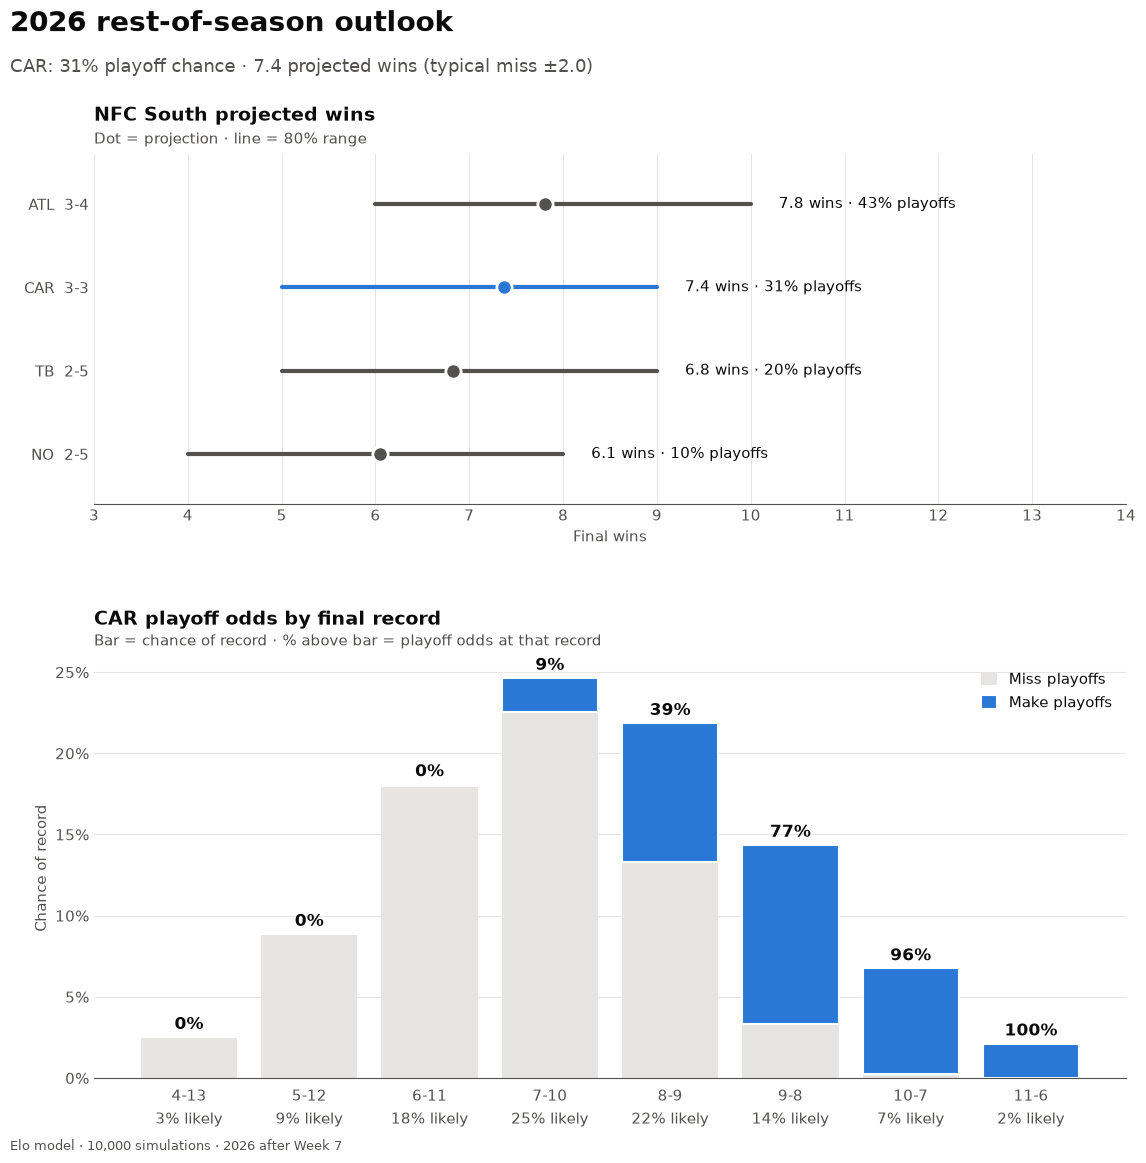

In [11]:
# Graph 1: rest-of-season outlook (division wins, playoff odds by final record)

# Carolina's final records, split into playoff and non-playoff seasons
outcomes = (pd.DataFrame({"wins": sims[:, COL[FOCUS_TEAM]], "playoffs": sim_playoff[:, COL[FOCUS_TEAM]]})
            .groupby("wins")["playoffs"].agg(["size", "sum"]))
outcomes["made"] = outcomes["sum"] / N_SIMS
outcomes["missed"] = (outcomes["size"] - outcomes["sum"]) / N_SIMS
outcomes["odds_at_record"] = outcomes["sum"] / outcomes["size"]
outcomes = outcomes[outcomes["size"] / N_SIMS >= 0.005]   # drop records under 0.5%

fig = plt.figure(figsize=(12, 12))
grid = fig.add_gridspec(2, 1, height_ratios=[1, 1.2], hspace=0.4, left=0.1, right=0.96, top=0.85, bottom=0.08)
ax0, ax1 = fig.add_subplot(grid[0]), fig.add_subplot(grid[1])

def panel_title(ax, title, subtitle):
    """Bold panel title with a one-line subtitle under it."""
    ax.set_title(title, loc="left", fontsize=14, fontweight="bold", color=INK, pad=24)
    ax.text(0, 1.03, subtitle, transform=ax.transAxes, fontsize=10.5, color=MUTED)

# 1. Division projected wins
order = div_proj.sort_values("proj_wins")
for y, (t, row) in enumerate(order.iterrows()):
    color = COLORS[0] if t == FOCUS_TEAM else MUTED
    ax0.plot([row["low"], row["high"]], [y, y], color=color, linewidth=3, solid_capstyle="round", zorder=2)
    ax0.plot(row["proj_wins"], y, marker="o", markersize=11, color=color,
             markeredgecolor="white", markeredgewidth=2, zorder=3)
    ax0.text(row["high"] + 0.3, y, f"{row['proj_wins']:.1f} wins · {row['playoff_pct']:.0%} playoffs",
             va="center", fontsize=11, color=INK)
ax0.set_yticks(range(len(order)))
ax0.set_yticklabels([f"{t}  {r['wins']:g}-{r['losses']:g}" for t, r in order.iterrows()], fontsize=12, color=INK)
ax0.set_ylim(-0.6, len(order) - 0.4)
ax0.set_xlim(3, 14)
ax0.set_xticks(range(3, 15))
ax0.grid(axis="x", color=GRID, linewidth=0.8)
ax0.set_xlabel("Final wins", color=MUTED, fontsize=11)
panel_title(ax0, f"{division} projected wins", "Dot = projection · line = 80% range")
style_axes(ax0)

# 2. Stacked bars: height = chance of each record, blue = the part that makes the playoffs.
#    Label above each bar = playoff odds at that record (blue / whole bar).
ax1.bar(outcomes.index, outcomes["missed"], width=0.8, color=GRID, zorder=2, label="Miss playoffs")
ax1.bar(outcomes.index, outcomes["made"], bottom=outcomes["missed"], width=0.8, color=COLORS[0],
        edgecolor="white", linewidth=1.5, zorder=2, label="Make playoffs")
for w, r in outcomes.iterrows():
    ax1.text(w, r["made"] + r["missed"] + 0.005, f"{r['odds_at_record']:.0%}", ha="center",
             fontsize=12, fontweight="bold", color=INK)
ax1.set_xticks(outcomes.index)
ax1.set_xticklabels([f"{w:g}-{17 - w:g}\n{r['size'] / N_SIMS:.0%} likely" for w, r in outcomes.iterrows()],
                    linespacing=1.6)
ax1.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}"))
ax1.grid(axis="y", color=GRID, linewidth=0.8)
ax1.set_ylabel("Chance of record", color=MUTED, fontsize=11)
ax1.legend(loc="upper right", frameon=False, fontsize=11, labelcolor=INK, handlelength=1, handleheight=1)
panel_title(ax1, f"{FOCUS_TEAM} playoff odds by final record", "Bar = chance of record · % above bar = playoff odds at that record")
style_axes(ax1)

# Titles placed for this taller figure
fig.text(0.03, 0.97, f"{SEASON} rest-of-season outlook", fontsize=20, fontweight="bold", color=INK, va="top")
fig.text(0.03, 0.93, f"{FOCUS_TEAM}: {team['playoff_pct']:.0%} playoff chance · {team['proj_wins']:.1f} projected wins "
         f"(typical miss ±{RMSE:.1f})", fontsize=13, color=MUTED, va="top")
fig.text(0.03, 0.02, f"Elo model · {N_SIMS:,} simulations · {SEASON} after Week {THROUGH_WEEK}", fontsize=9, color=MUTED)
fig.savefig(FORECAST_DIR / f"{SEASON}_thru_wk{THROUGH_WEEK:02d}_{FOCUS_TEAM}_outlook.png", dpi=200, facecolor="white")
plt.show()

,point_diff,playoff_pct
change,,
-3,-4.961,0.141
-2,-3.961,0.189
-1,-2.961,0.238
0,-1.961,0.308
1,-0.961,0.380
2,0.039,0.463
3,1.039,0.542


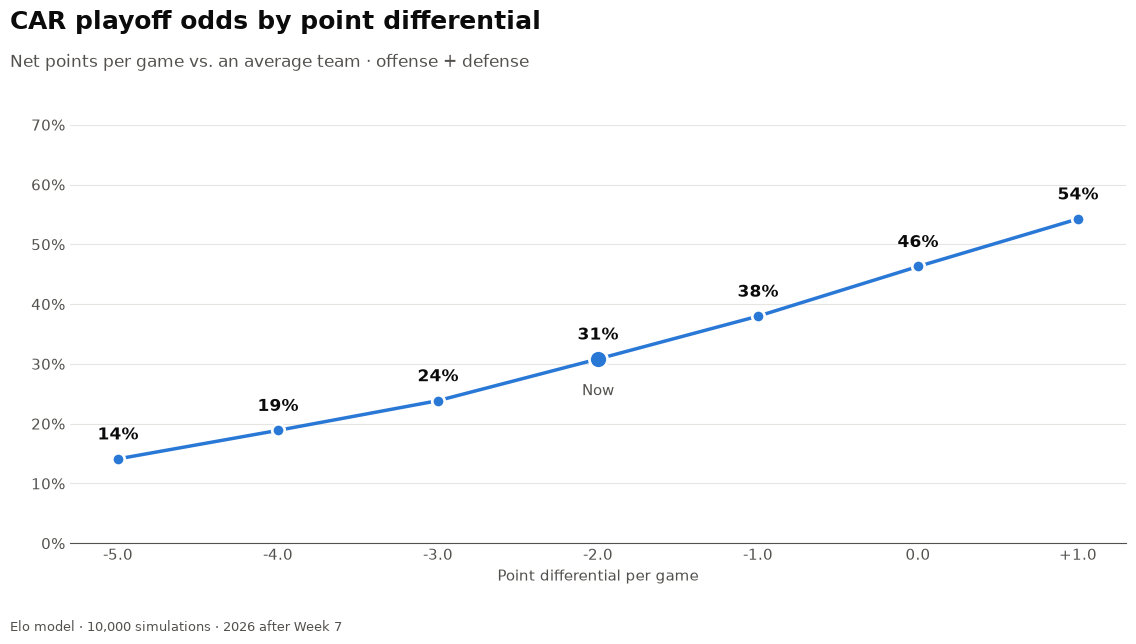

In [12]:
# Graph 2: playoff odds as Carolina's point differential rises or falls
# Point differential per game vs. an average team = (Elo - base) / spread_divisor.
# Shift Carolina's Elo by 25 per point and rerun the season; covers offense and defense.
current_diff = (team["elo"] - DEFAULT_PARAMS["base"]) / DEFAULT_PARAMS["spread_divisor"]
changes = np.arange(-3, 4)
diff_odds = pd.DataFrame({
    "point_diff": current_diff + changes,
    "playoff_pct": [project_season(SEASON, THROUGH_WEEK, DEFAULT_PARAMS, N_SIMS,
                                   shift={FOCUS_TEAM: c * DEFAULT_PARAMS["spread_divisor"]})[0]
                    .loc[FOCUS_TEAM, "playoff_pct"] for c in changes],
}, index=pd.Index(changes, name="change"))
display(diff_odds.round(3))

fig, ax = plt.subplots(figsize=(12, 6.75))
fig.subplots_adjust(left=0.08, right=0.96, top=0.78, bottom=0.16)

ax.plot(diff_odds["point_diff"], diff_odds["playoff_pct"], color=COLORS[0], linewidth=2.5, zorder=2)
for c, r in diff_odds.iterrows():
    now = c == 0
    ax.plot(r["point_diff"], r["playoff_pct"], marker="o", markersize=13 if now else 9, color=COLORS[0],
            markeredgecolor="white", markeredgewidth=2, zorder=3)
    ax.annotate(f"{r['playoff_pct']:.0%}", (r["point_diff"], r["playoff_pct"]), textcoords="offset points",
                xytext=(0, 14), ha="center", fontsize=12, fontweight="bold", color=INK)
now = diff_odds.loc[0]
ax.annotate("Now", (now["point_diff"], now["playoff_pct"]), textcoords="offset points",
            xytext=(0, -26), ha="center", fontsize=11, color=MUTED)

ax.set_xticks(diff_odds["point_diff"])
ax.set_xticklabels([f"{d:+.1f}" if round(d, 1) else "0.0" for d in diff_odds["point_diff"]])
ax.set_ylim(0, 0.7)
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}"))
ax.grid(axis="y", color=GRID, linewidth=0.8)
ax.set_xlabel("Point differential per game", color=MUTED, fontsize=11)
style_axes(ax)

add_titles(fig, f"{FOCUS_TEAM} playoff odds by point differential",
           "Net points per game vs. an average team · offense + defense")
fig.savefig(FORECAST_DIR / f"{SEASON}_thru_wk{THROUGH_WEEK:02d}_{FOCUS_TEAM}_point_diff.png", dpi=200, facecolor="white")
plt.show()